In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/jiejiea/ai4i-2020-predictive-maintenance/__results__.html
/kaggle/input/notebooks/jiejiea/ai4i-2020-predictive-maintenance/__resultx__.html
/kaggle/input/notebooks/jiejiea/ai4i-2020-predictive-maintenance/__notebook__.ipynb
/kaggle/input/notebooks/jiejiea/ai4i-2020-predictive-maintenance/__output__.json
/kaggle/input/notebooks/jiejiea/ai4i-2020-predictive-maintenance/custom.css
/kaggle/input/notebooks/jiejiea/ai4i-2020-predictive-maintenance/__results___files/__results___36_3.png
/kaggle/input/notebooks/jiejiea/ai4i-2020-predictive-maintenance/__results___files/__results___9_0.png
/kaggle/input/notebooks/jiejiea/ai4i-2020-predictive-maintenance/__results___files/__results___37_2.png
/kaggle/input/notebooks/jiejiea/ai4i-2020-predictive-maintenance/__results___files/__results___36_2.png
/kaggle/input/notebooks/jiejiea/ai4i-2020-predictive-maintenance/__results___files/__results___38_2.png
/kaggle/input/notebooks/jiejiea/ai4i-2020-predictive-maintenance/__results__

In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv('/kaggle/input/datasets/stephanmatzka/predictive-maintenance-dataset-ai4i-2020/ai4i2020.csv')

In [4]:
df


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [6]:
df.describe()


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [7]:
df["Type"].value_counts()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

In [8]:
normal_df = df[df["Machine failure"] == 0]
failure_df = df[df["Machine failure"] == 1]

print(normal_df.shape)
print(failure_df.shape)

(9661, 14)
(339, 14)


In [9]:
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

In [10]:
X_normal = normal_df[features]
X_failure = failure_df[features]

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_val = train_test_split(
    X_normal,
    test_size=0.2,
    random_state=42
)

In [12]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

X_failure_scaled = scaler.transform(X_failure)

In [13]:
print(X_train_scaled.shape)

(7728, 5)


In [14]:
import tensorflow as tf
from tensorflow.keras import layers, Model

input_dim = X_train_scaled.shape[1]

inputs = tf.keras.Input(shape=(input_dim,))

# Encoder
x = layers.Dense(4, activation="relu")(inputs)
bottleneck = layers.Dense(2, activation="relu")(x)

# Decoder
x = layers.Dense(4, activation="relu")(bottleneck)
outputs = layers.Dense(input_dim, activation="linear")(x)

autoencoder = Model(inputs, outputs)

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

autoencoder.summary()

2026-06-18 15:47:59.629618: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1781797679.906418      16 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781797679.983700      16 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781797680.685799      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781797680.685860      16 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781797680.685863      16 computation_placer.cc:177] computation placer alr

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 5)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            10 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            12 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │            25 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71 (284.00 B)

 Trainable params: 71 (284.00 B)

 Non-trainable params: 0 (0.00 B)

In [15]:
history = autoencoder.fit(
    X_train_scaled,
    X_train_scaled,
    epochs=50,
    batch_size=32,
    validation_data=(X_val_scaled, X_val_scaled),
    verbose=1
)

Epoch 1/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.9892 - val_loss: 0.8427
Epoch 2/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6846 - val_loss: 0.5814
Epoch 3/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.5465 - val_loss: 0.5375
Epoch 4/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4883 - val_loss: 0.4487
Epoch 5/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3847 - val_loss: 0.3662
Epoch 6/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3309 - val_loss: 0.3275
Epoch 7/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3040 - val_loss: 0.3035
Epoch 8/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2856 - val_loss: 0.2846
Epoch 9/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2704 - val_loss: 0.2698
Epoch 10/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2582 - val_loss: 0.2584
Epoch 11/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2495 - val_loss: 0.2516
Epoch 12/50
242/242 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

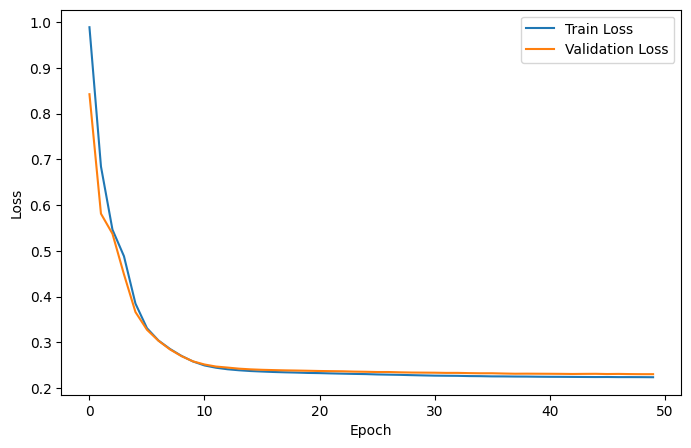

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# Anomaly

In [17]:
val_predictions = autoencoder.predict(X_val_scaled)

61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [18]:
import numpy as np

val_errors = np.mean(
    np.square(X_val_scaled - val_predictions),
    axis=1
)

In [19]:
failure_predictions = autoencoder.predict(
    X_failure_scaled
)

failure_errors = np.mean(
    np.square(
        X_failure_scaled - failure_predictions
    ),
    axis=1
)

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


In [20]:
threshold = np.percentile(val_errors, 90)

print("Threshold:", threshold)

Threshold: 0.5397921553794424


In [21]:
failure_predictions = autoencoder.predict(
    X_failure_scaled
)

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


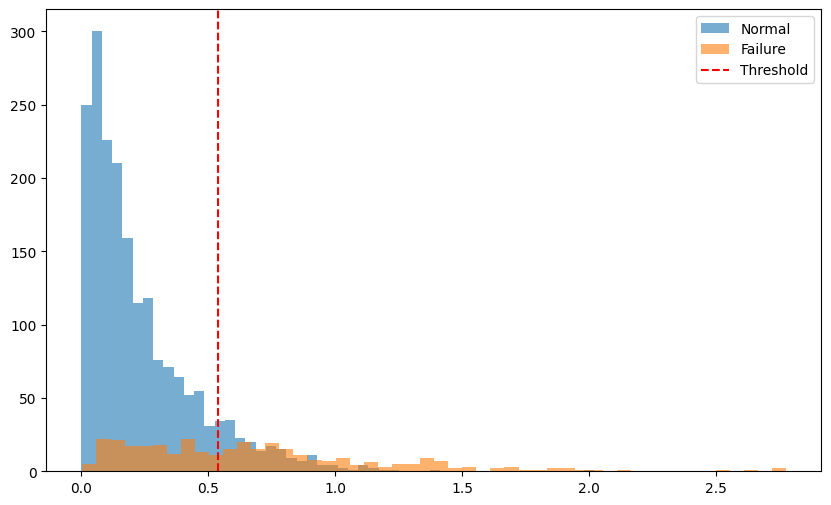

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

plt.hist(
    val_errors,
    bins=50,
    alpha=0.6,
    label="Normal"
)

plt.hist(
    failure_errors,
    bins=50,
    alpha=0.6,
    label="Failure"
)

plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    label="Threshold"
)

plt.legend()
plt.show()

In [23]:
print(len(failure_errors))
print(np.sum(failure_errors > threshold))

339
182


In [24]:
from sklearn.metrics import confusion_matrix

normal_pred = (val_errors > threshold).astype(int)
failure_pred = (failure_errors > threshold).astype(int)

y_true = np.concatenate([
    np.zeros(len(val_errors)),
    np.ones(len(failure_errors))
])

y_pred = np.concatenate([
    normal_pred,
    failure_pred
])

print(confusion_matrix(y_true, y_pred))

[[1739  194]
 [ 157  182]]


In [25]:
def detect_anomaly(row):
    
    row_scaled = scaler.transform(row)

    reconstruction = autoencoder.predict(
        row_scaled,
        verbose=0
    )

    error = np.mean(
        np.square(
            row_scaled - reconstruction
        )
    )

    if error > threshold:
        return "Anomaly", error

    return "Normal", error

In [26]:
for i in range(10):

    sample = X_failure.iloc[[i]]

    status, error = detect_anomaly(sample)

    print(
        f"Machine {i+1}: "
        f"{status} | Error={error:.3f}"
    )

Machine 1: Anomaly | Error=1.630
Machine 2: Anomaly | Error=1.345
Machine 3: Normal | Error=0.245
Machine 4: Anomaly | Error=1.363
Machine 5: Anomaly | Error=0.648
Machine 6: Normal | Error=0.168
Machine 7: Anomaly | Error=0.793
Machine 8: Normal | Error=0.444
Machine 9: Anomaly | Error=0.954
Machine 10: Anomaly | Error=0.919


In [27]:
print(threshold)

0.5397921553794424


In [28]:
sample = X_failure.iloc[[7]]

print(sample)

     Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
207                298.4                    308.7                    1421   

     Torque [Nm]  Tool wear [min]  
207         60.7              119  
